this is the redone data exploration for the dataset 

In [1]:
ls

data_exploration.ipynb


In [2]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [3]:
og_apps = pd.read_csv('../dataset/application_record.csv') # go back to 1 wd 
og_apps.head()


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [4]:
og_record = pd.read_csv('../dataset/credit_record.csv')
og_record.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [5]:
apps: pd.DataFrame = og_apps.copy(deep = True ) # defined type pd DF so that pylance doenst miss out on definitions
records: pd.DataFrame = og_record.copy(deep = True)

In [6]:
apps.columns 

Index(['ID', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN',
       'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE',
       'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS'],
      dtype='object')

In [7]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

In [8]:
apps.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


In [9]:
corr_matrix = apps.corr(numeric_only=True)
corr_matrix

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
ID,1.000000,-0.005178,0.011179,-0.004994,-0.002467,NaN,-0.023319,-0.018992,0.032875,-0.001862
CNT_CHILDREN,-0.005178,1.000000,0.019177,0.349088,-0.241535,NaN,0.038418,-0.038266,0.028457,0.884781
AMT_INCOME_TOTAL,0.011179,0.019177,1.000000,0.053775,-0.141291,NaN,-0.033635,0.004444,0.112139,0.011454
DAYS_BIRTH,-0.004994,0.349088,0.053775,1.000000,-0.617908,NaN,0.171829,-0.037984,0.096752,0.306179
DAYS_EMPLOYED,-0.002467,-0.241535,-0.141291,-0.617908,1.000000,NaN,-0.232208,0.004868,-0.074372,-0.234373
FLAG_MOBIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAG_WORK_PHONE,-0.023319,0.038418,-0.033635,0.171829,-0.232208,NaN,1.000000,0.290066,-0.060915,0.049777
FLAG_PHONE,-0.018992,-0.038266,0.004444,-0.037984,0.004868,NaN,0.290066,1.000000,-0.001170,-0.024213
FLAG_EMAIL,0.032875,0.028457,0.112139,0.096752,-0.074372,NaN,-0.060915,-0.001170,1.000000,0.022054
CNT_FAM_MEMBERS,-0.001862,0.884781,0.011454,0.306179,-0.234373,NaN,0.049777,-0.024213,0.022054,1.000000


flag_mobil is nan, check whether this is due to: 
- no variation in data
- nan values in column 
- inf / - inf values in column 

In [10]:
apps['FLAG_MOBIL'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 438557 entries, 0 to 438556
Series name: FLAG_MOBIL
Non-Null Count   Dtype
--------------   -----
438557 non-null  int64
dtypes: int64(1)
memory usage: 3.3 MB


In [11]:
# there is just 1 value, which is flag 1 
# so, the feature is not informative and can be dropped 
apps.drop(columns=['FLAG_MOBIL'], axis = 1, inplace = True )
apps.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,0,1,1,Sales staff,1.0


<Axes: >

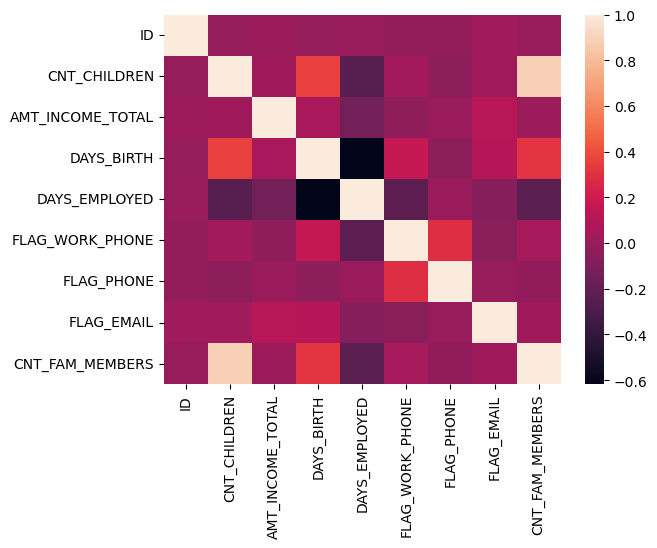

In [12]:
# now look at the heatmap again 
sns.heatmap(apps.corr(numeric_only=True))


this correlation matrix will be more informative when the object type columns are encoeded and involved in the correlation matrix 

In [13]:
# encode the object type columns 
apps.select_dtypes(include=['object'], )

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE
0,M,Y,Y,Working,Higher education,Civil marriage,Rented apartment,NaN
1,M,Y,Y,Working,Higher education,Civil marriage,Rented apartment,NaN
2,M,Y,Y,Working,Secondary / secondary special,Married,House / apartment,Security staff
3,F,N,Y,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff
4,F,N,Y,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff
...,...,...,...,...,...,...,...,...
438552,M,N,Y,Pensioner,Secondary / secondary special,Separated,House / apartment,NaN
438553,F,N,N,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers
438554,F,N,N,Commercial associate,Higher education,Single / not married,With parents,Sales staff
438555,F,N,Y,Pensioner,Secondary / secondary special,Married,House / apartment,NaN


In [28]:
object_columns = apps.select_dtypes(include = 'object').columns.tolist()
object_columns

['CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE']

In [15]:
# see what transformations have to be done on these columns then do to main df 
objectapps : pd.DataFrame = apps[object_columns]
objectapps

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE
0,M,Y,Y,Working,Higher education,Civil marriage,Rented apartment,NaN
1,M,Y,Y,Working,Higher education,Civil marriage,Rented apartment,NaN
2,M,Y,Y,Working,Secondary / secondary special,Married,House / apartment,Security staff
3,F,N,Y,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff
4,F,N,Y,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff
...,...,...,...,...,...,...,...,...
438552,M,N,Y,Pensioner,Secondary / secondary special,Separated,House / apartment,NaN
438553,F,N,N,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers
438554,F,N,N,Commercial associate,Higher education,Single / not married,With parents,Sales staff
438555,F,N,Y,Pensioner,Secondary / secondary special,Married,House / apartment,NaN


In [16]:
objectapps.isna().sum()

CODE_GENDER                 0
FLAG_OWN_CAR                0
FLAG_OWN_REALTY             0
NAME_INCOME_TYPE            0
NAME_EDUCATION_TYPE         0
NAME_FAMILY_STATUS          0
NAME_HOUSING_TYPE           0
OCCUPATION_TYPE        134203
dtype: int64

In [17]:
apps.isna().sum()

ID                          0
CODE_GENDER                 0
FLAG_OWN_CAR                0
FLAG_OWN_REALTY             0
CNT_CHILDREN                0
AMT_INCOME_TOTAL            0
NAME_INCOME_TYPE            0
NAME_EDUCATION_TYPE         0
NAME_FAMILY_STATUS          0
NAME_HOUSING_TYPE           0
DAYS_BIRTH                  0
DAYS_EMPLOYED               0
FLAG_WORK_PHONE             0
FLAG_PHONE                  0
FLAG_EMAIL                  0
OCCUPATION_TYPE        134203
CNT_FAM_MEMBERS             0
dtype: int64

In [18]:
# only occupation type has null, see how to deal with that 
    # first find proportion of nulls
134203/ apps.shape[0]

0.30601039317580153

In [19]:
# 30 percent of the occupation type feature is missing, if the feature is generally uninformative, it can be removed 
# encode the feature and see if it has to be dropped after generating heatmap 
objectapps.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE
0,M,Y,Y,Working,Higher education,Civil marriage,Rented apartment,NaN
1,M,Y,Y,Working,Higher education,Civil marriage,Rented apartment,NaN
2,M,Y,Y,Working,Secondary / secondary special,Married,House / apartment,Security staff
3,F,N,Y,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff
4,F,N,Y,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff


In [21]:
# figure out how to encode the categorical variables 
    # there can be oridinal ordered encoding 
    # or nominal plain encoding - get dummies or one hot encoder for indicator columns (for high cardinality features)


for col in object_columns: 
    c = objectapps[col].value_counts(dropna= False )
    print(col, c)

CODE_GENDER CODE_GENDER
F    294440
M    144117
Name: count, dtype: int64
FLAG_OWN_CAR FLAG_OWN_CAR
N    275459
Y    163098
Name: count, dtype: int64
FLAG_OWN_REALTY FLAG_OWN_REALTY
Y    304074
N    134483
Name: count, dtype: int64
NAME_INCOME_TYPE NAME_INCOME_TYPE
Working                 226104
Commercial associate    100757
Pensioner                75493
State servant            36186
Student                     17
Name: count, dtype: int64
NAME_EDUCATION_TYPE NAME_EDUCATION_TYPE
Secondary / secondary special    301821
Higher education                 117522
Incomplete higher                 14851
Lower secondary                    4051
Academic degree                     312
Name: count, dtype: int64
NAME_FAMILY_STATUS NAME_FAMILY_STATUS
Married                 299828
Single / not married     55271
Civil marriage           36532
Separated                27251
Widow                    19675
Name: count, dtype: int64
NAME_HOUSING_TYPE NAME_HOUSING_TYPE
House / apartment      393831
Wi

In [23]:
# CODE_GENDER, FLAG_OWN_CAR, FLAG_OWN_REALTY = binary encoding 
# NAME_INCOME_TYPE,NAME_FAMILY_STATUS, NAME_HOUSING_TYPE,OCCUPATION_TYPE  = nominal encoding 
    # occupation type is just too high cardinality to do one hot encoding as it is 
    # for seeing the heatmap, just do plain label encoding 
# NAME_EDUCATION_TYPE = ordinal encoding 

# label encoder all cols except NAME_EDUCATION_TYPE. NAME_EDUCATION_TYPE will be ordinal encoding 
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
# column transformer to horizontal processsing 
labels = object_columns.copy() # auto deep 
labels.remove('NAME_EDUCATION_TYPE')
ordinals = ['NAME_EDUCATION_TYPE']

labels, ordinals

(['CODE_GENDER',
  'FLAG_OWN_CAR',
  'FLAG_OWN_REALTY',
  'NAME_INCOME_TYPE',
  'NAME_FAMILY_STATUS',
  'NAME_HOUSING_TYPE',
  'OCCUPATION_TYPE'],
 ['NAME_EDUCATION_TYPE'])

In [37]:
apps['NAME_EDUCATION_TYPE'].unique()

array(['Higher education', 'Secondary / secondary special',
       'Incomplete higher', 'Lower secondary', 'Academic degree'],
      dtype=object)

In [ ]:
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

In [31]:
temp = apps.copy(deep = True)

In [52]:
# label encoder gives 1d array, rather than 2 - workaround is to use ordinal encoder 
    # note: unknown_value=-1 -- doesn't crash when doing transform and comes across unseen value
    # that unseen value just gets encoded to - 1
    # encoded_missing_value=-1 -- change missing vals to -1, or np.nan
col_transfrormer = ColumnTransformer(
    transformers=[
        # ('labelencoding', LabelEncoder(), labels ), # auto deals with nan, but cant use becuase of dim issue 
        ('labelencoding', OrdinalEncoder(encoded_missing_value=-1), labels ),
        ('ordinalencoding', OrdinalEncoder(categories = [education_order]), ordinals)
    ]
    , 
    remainder= 'passthrough', 
    verbose_feature_names_out=False
    
).set_output(transform='pandas')

res= col_transfrormer.fit_transform(temp)
res

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,NAME_EDUCATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,1.0,4.0,0.0,4.0,-1.0,3.0,5008804,0,427500.0,-12005,-4542,1,0,0,2.0
1,1.0,1.0,1.0,4.0,0.0,4.0,-1.0,3.0,5008805,0,427500.0,-12005,-4542,1,0,0,2.0
2,1.0,1.0,1.0,4.0,1.0,1.0,16.0,1.0,5008806,0,112500.0,-21474,-1134,0,0,0,2.0
3,0.0,0.0,1.0,0.0,3.0,1.0,14.0,1.0,5008808,0,270000.0,-19110,-3051,0,1,1,1.0
4,0.0,0.0,1.0,0.0,3.0,1.0,14.0,1.0,5008809,0,270000.0,-19110,-3051,0,1,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,1.0,0.0,1.0,1.0,2.0,1.0,-1.0,1.0,6840104,0,135000.0,-22717,365243,0,0,0,1.0
438553,0.0,0.0,0.0,4.0,3.0,1.0,8.0,1.0,6840222,0,103500.0,-15939,-3007,0,0,0,1.0
438554,0.0,0.0,0.0,0.0,3.0,5.0,14.0,3.0,6841878,0,54000.0,-8169,-372,1,0,0,1.0
438555,0.0,0.0,1.0,1.0,1.0,1.0,-1.0,1.0,6842765,0,72000.0,-21673,365243,0,0,0,2.0


In [53]:
res = apps.copy(deep  = True)
res= col_transfrormer.transform(res)
res.head()


,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,NAME_EDUCATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,1.0,4.0,0.0,4.0,-1.0,3.0,5008804,0,427500.0,-12005,-4542,1,0,0,2.0
1,1.0,1.0,1.0,4.0,0.0,4.0,-1.0,3.0,5008805,0,427500.0,-12005,-4542,1,0,0,2.0
2,1.0,1.0,1.0,4.0,1.0,1.0,16.0,1.0,5008806,0,112500.0,-21474,-1134,0,0,0,2.0
3,0.0,0.0,1.0,0.0,3.0,1.0,14.0,1.0,5008808,0,270000.0,-19110,-3051,0,1,1,1.0
4,0.0,0.0,1.0,0.0,3.0,1.0,14.0,1.0,5008809,0,270000.0,-19110,-3051,0,1,1,1.0


In [ ]:
res.select_dtypes(include='object') # no object dtypes anymore 

""
0
1
2
3
4
...
438552
438553
438554
438555


<Axes: >

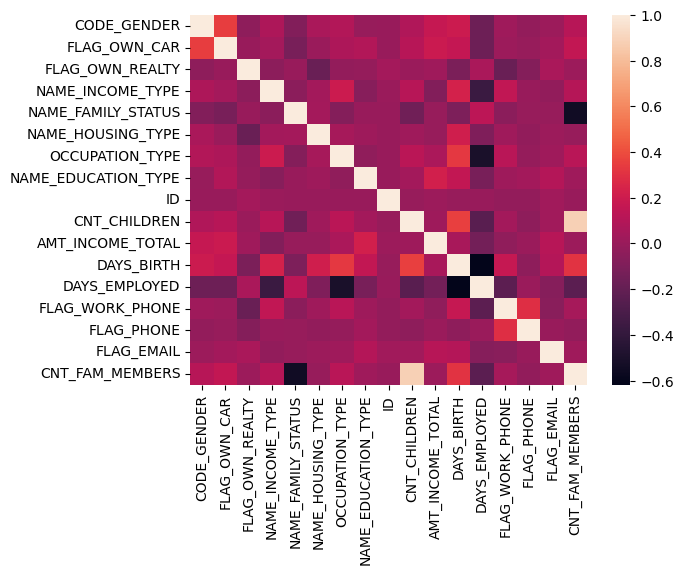

In [ ]:
sns.heatmap(res.corr(numeric_only=True)) # nans are automatically dropped, so the df is transformed to have -1 as missing values 

this suggests that the encoded features are fine and generally informative and can be kept in df. 
the occupation type has missing values, but that can just be encoded in as another value -1 
education order is kept as ordinal. 

now make a decision how to deal with nominal encoding, keep as integer encoding or use one hot encoding? 

In [55]:
# do one hot encoding for nominal categories and see how that looks in heatmap 
apps.columns

Index(['ID', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN',
       'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL',
       'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS'],
      dtype='object')

In [56]:
categorical= apps.select_dtypes(include = 'object').columns.to_list()
categorical

['CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE']

In [ ]:
# binary = CODE_GENDER,FLAG_OWN_CAR, FLAG_OWN_REALTY


col_transfrormer = ColumnTransformer(
    transformers=[('binaryencoder', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ),
                ('onehotencoding', OneHotEncoder(sparse_output=False), [
                                        'NAME_INCOME_TYPE',
                                        'NAME_FAMILY_STATUS',
                                        'NAME_HOUSING_TYPE',
                                        'OCCUPATION_TYPE']), # nan = missing value column
                    ('ordinalencoding', OrdinalEncoder(categories=[education_order]), ['NAME_EDUCATION_TYPE'] )]
                    , # use drop = first if wanted 
                remainder= 'passthrough', 
                verbose_feature_names_out=False 
).set_output(transform='pandas')

res= apps.copy(deep =True)
res = col_transfrormer.fit_transform(res)
res.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,NAME_INCOME_TYPE_Working,NAME_FAMILY_STATUS_Civil marriage,NAME_FAMILY_STATUS_Married,...,NAME_EDUCATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,3.0,5008804,0,427500.0,-12005,-4542,1,0,0,2.0
1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,3.0,5008805,0,427500.0,-12005,-4542,1,0,0,2.0
2,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,5008806,0,112500.0,-21474,-1134,0,0,0,2.0
3,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,5008808,0,270000.0,-19110,-3051,0,1,1,1.0
4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,5008809,0,270000.0,-19110,-3051,0,1,1,1.0


In [68]:
res.columns

Index(['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_INCOME_TYPE_Commercial associate', 'NAME_INCOME_TYPE_Pensioner',
       'NAME_INCOME_TYPE_State servant', 'NAME_INCOME_TYPE_Student',
       'NAME_INCOME_TYPE_Working', 'NAME_FAMILY_STATUS_Civil marriage',
       'NAME_FAMILY_STATUS_Married', 'NAME_FAMILY_STATUS_Separated',
       'NAME_FAMILY_STATUS_Single / not married', 'NAME_FAMILY_STATUS_Widow',
       'NAME_HOUSING_TYPE_Co-op apartment',
       'NAME_HOUSING_TYPE_House / apartment',
       'NAME_HOUSING_TYPE_Municipal apartment',
       'NAME_HOUSING_TYPE_Office apartment',
       'NAME_HOUSING_TYPE_Rented apartment', 'NAME_HOUSING_TYPE_With parents',
       'OCCUPATION_TYPE_Accountants', 'OCCUPATION_TYPE_Cleaning staff',
       'OCCUPATION_TYPE_Cooking staff', 'OCCUPATION_TYPE_Core staff',
       'OCCUPATION_TYPE_Drivers', 'OCCUPATION_TYPE_HR staff',
       'OCCUPATION_TYPE_High skill tech staff', 'OCCUPATION_TYPE_IT staff',
       'OCCUPATION_TYPE_Laborers', 

<Axes: >

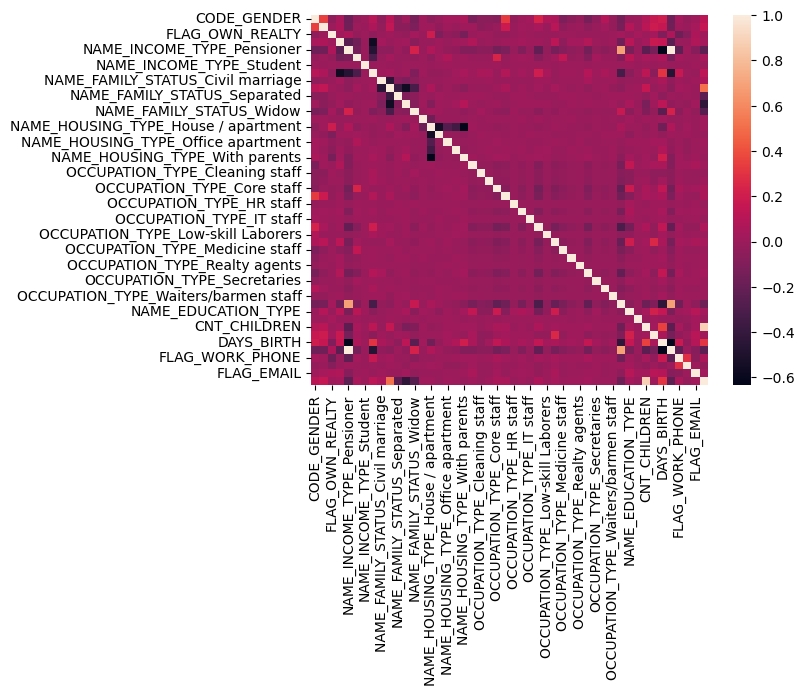

In [69]:
sns.heatmap(res.corr())

In [70]:
res.corr()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,NAME_INCOME_TYPE_Working,NAME_FAMILY_STATUS_Civil marriage,NAME_FAMILY_STATUS_Married,...,NAME_EDUCATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
CODE_GENDER,1.000000,0.346580,-0.041982,0.044620,-0.168437,-0.024530,0.000322,0.103174,-0.039790,0.109990,...,-0.007651,0.000545,0.086101,0.168807,0.193781,-0.167255,0.026050,-0.022300,0.011416,0.114188
FLAG_OWN_CAR,0.346580,1.000000,-0.001312,0.065853,-0.165839,0.004399,-0.003275,0.067457,-0.027917,0.140325,...,0.095991,0.000063,0.115138,0.188203,0.163770,-0.165372,0.008061,-0.006606,0.038601,0.156943
FLAG_OWN_REALTY,-0.041982,-0.001312,1.000000,0.010698,0.064382,-0.025496,0.000963,-0.043612,-0.002622,0.014737,...,-0.013909,0.042709,0.001560,0.025443,-0.106908,0.064281,-0.177372,-0.078227,0.062483,0.008070
NAME_INCOME_TYPE_Commercial associate,0.044620,0.065853,0.010698,1.000000,-0.249040,-0.163781,-0.003400,-0.563418,0.025635,-0.006882,...,0.112127,-0.006948,0.033122,0.172147,0.157913,-0.247462,-0.009076,-0.004058,0.077707,0.031037
NAME_INCOME_TYPE_Pensioner,-0.168437,-0.165839,0.064382,-0.249040,1.000000,-0.136747,-0.002839,-0.470419,-0.039752,-0.052126,...,-0.120454,-0.002501,-0.242349,-0.140646,-0.621478,0.998563,-0.231718,0.005434,-0.074878,-0.234841
NAME_INCOME_TYPE_State servant,-0.024530,0.004399,-0.025496,-0.163781,-0.136747,1.000000,-0.001867,-0.309371,-0.013475,0.032714,...,0.116195,0.008877,0.044673,0.036493,0.068587,-0.138595,0.031567,-0.001104,0.004120,0.049012
NAME_INCOME_TYPE_Student,0.000322,-0.003275,0.000963,-0.003400,-0.002839,-0.001867,1.000000,-0.006423,0.002099,-0.002065,...,0.005893,-0.006989,-0.001145,-0.001578,0.002118,-0.002828,-0.003173,-0.003958,0.010800,-0.001349
NAME_INCOME_TYPE_Working,0.103174,0.067457,-0.043612,-0.563418,-0.470419,-0.309371,-0.006423,1.000000,0.015841,0.027183,...,-0.067440,0.002937,0.130603,-0.058736,0.298736,-0.469644,0.165332,-0.000032,-0.011252,0.124300
NAME_FAMILY_STATUS_Civil marriage,-0.039790,-0.027917,-0.002622,0.025635,-0.039752,-0.013475,0.002099,0.015841,1.000000,-0.443162,...,-0.019637,-0.004170,-0.019459,0.014949,0.053467,-0.039112,0.017411,-0.006048,0.009296,0.062427
NAME_FAMILY_STATUS_Married,0.109990,0.140325,0.014737,-0.006882,-0.052126,0.032714,-0.002065,0.027183,-0.443162,1.000000,...,0.002389,0.007021,0.161511,-0.016373,0.015627,-0.052841,0.026007,0.016475,-0.007458,0.511106


this is a good encoding result: 
- transformers=[('binaryencoder', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ),
                ('onehotencoding', OneHotEncoder(sparse_output=False), [
                                        'NAME_INCOME_TYPE',
                                        'NAME_FAMILY_STATUS',
                                        'NAME_HOUSING_TYPE',
                                        'OCCUPATION_TYPE']), # nan = missing value column
                    ('ordinalencoding', OrdinalEncoder(categories=[education_order]), ['NAME_EDUCATION_TYPE'] )]



now work on scaling 
since nn will be used, dont allow for example: ordinal column ranging from 0 to 4 alongside scaled features ranging from -1 to 1. use minmax scaler applied to mini df/ end of mini ordinal encoding pipeline: ord_pipeline = Pipeline([
    ('encode', OrdinalEncoder(categories=[education_order])),
    ('scale', MinMaxScaler())
])

no scaling the binary features 

In [97]:
# first figure out how to put minmax scaler on top of ordinal encoder 
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler, FunctionTransformer

In [72]:
binary = ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ]  # nominal 
one_hot = ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'] # nominal 

ordinal = ['NAME_EDUCATION_TYPE']
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

ordinal_pipeline = Pipeline(
    steps = [('ordinal_endoding', OrdinalEncoder(categories= [education_order])), 
             ('scaling', MinMaxScaler())]
)

transformer = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), binary), 
        ('onehot', OneHotEncoder(sparse_output=False), one_hot), 
        ('ordinal', ordinal_pipeline, ordinal )
    ], 
    remainder='passthrough', 
    verbose_feature_names_out=False
).set_output(transform='pandas')


fitted = transformer.fit_transform(apps)
fitted.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,NAME_INCOME_TYPE_Working,NAME_FAMILY_STATUS_Civil marriage,NAME_FAMILY_STATUS_Married,...,NAME_EDUCATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.75,5008804,0,427500.0,-12005,-4542,1,0,0,2.0
1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.75,5008805,0,427500.0,-12005,-4542,1,0,0,2.0
2,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.25,5008806,0,112500.0,-21474,-1134,0,0,0,2.0
3,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.25,5008808,0,270000.0,-19110,-3051,0,1,1,1.0
4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.25,5008809,0,270000.0,-19110,-3051,0,1,1,1.0


In [74]:
# name education type is between 0 and 1 now 
fitted.columns

Index(['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_INCOME_TYPE_Commercial associate', 'NAME_INCOME_TYPE_Pensioner',
       'NAME_INCOME_TYPE_State servant', 'NAME_INCOME_TYPE_Student',
       'NAME_INCOME_TYPE_Working', 'NAME_FAMILY_STATUS_Civil marriage',
       'NAME_FAMILY_STATUS_Married', 'NAME_FAMILY_STATUS_Separated',
       'NAME_FAMILY_STATUS_Single / not married', 'NAME_FAMILY_STATUS_Widow',
       'NAME_HOUSING_TYPE_Co-op apartment',
       'NAME_HOUSING_TYPE_House / apartment',
       'NAME_HOUSING_TYPE_Municipal apartment',
       'NAME_HOUSING_TYPE_Office apartment',
       'NAME_HOUSING_TYPE_Rented apartment', 'NAME_HOUSING_TYPE_With parents',
       'OCCUPATION_TYPE_Accountants', 'OCCUPATION_TYPE_Cleaning staff',
       'OCCUPATION_TYPE_Cooking staff', 'OCCUPATION_TYPE_Core staff',
       'OCCUPATION_TYPE_Drivers', 'OCCUPATION_TYPE_HR staff',
       'OCCUPATION_TYPE_High skill tech staff', 'OCCUPATION_TYPE_IT staff',
       'OCCUPATION_TYPE_Laborers', 

In [76]:
# this column transform with ordinal pipeline is working well to scale the categorical features 
# now work on scaling the numerical features depending on their distributions 
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_WORK_PHONE      438557 non-null  int64  
 13  FLAG_PHONE           438557 non-null  int64  
 14  FLAG_EMAIL           438557 non-null  int64  
 15  OCCUPATION_TYPE  

In [77]:
numerical = apps.select_dtypes('number').columns.to_list()
numerical 

['ID',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'FLAG_WORK_PHONE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'CNT_FAM_MEMBERS']

In [80]:
numerical = ['ID',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'CNT_FAM_MEMBERS']

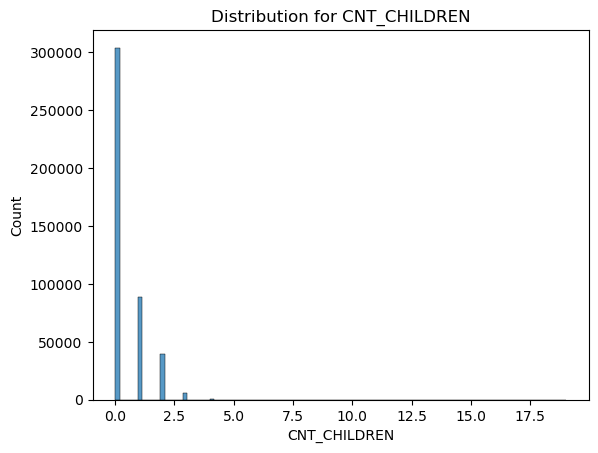

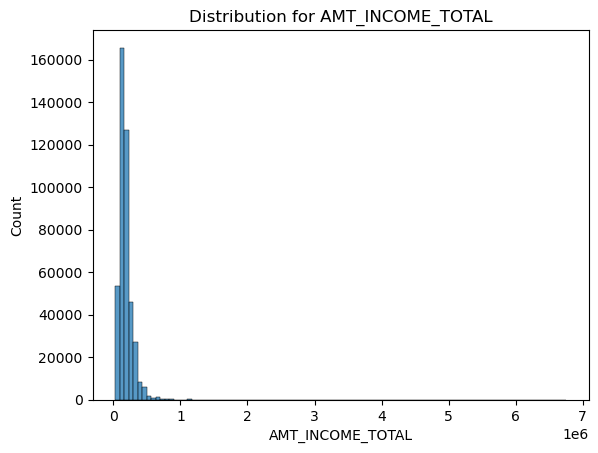

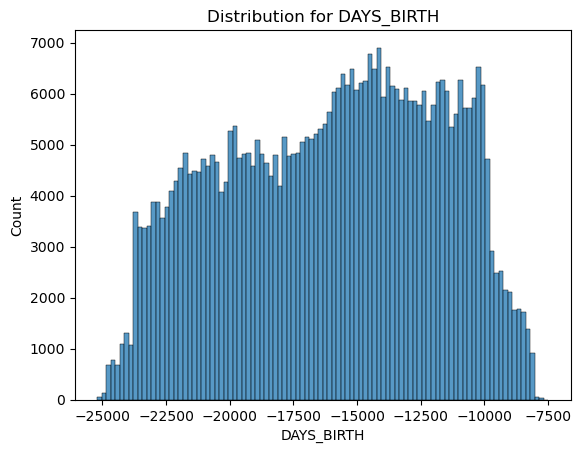

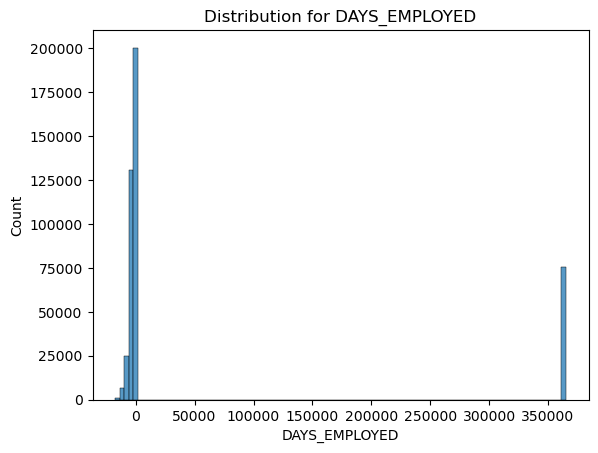

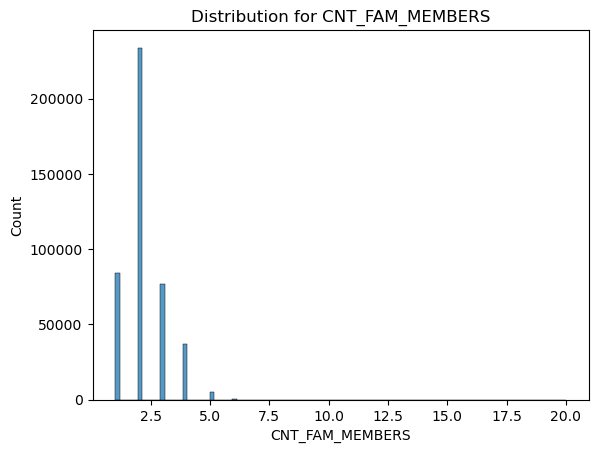

In [81]:
# see the distributions of these numerical features 
for feature in numerical[1:]: 
    sns.histplot(apps[feature], bins= 100 )
    plt.title('Distribution for '+feature)
    plt.show()

In [82]:
apps[numerical].describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,20.000000


In [ ]:
apps[numerical].skew().sort_values(ascending=False) # high skew if < -1 or > + 1 // .5s mean medium // less than .5 closer to 0 is symmetrical 

AMT_INCOME_TOTAL    8.834066
CNT_CHILDREN        1.806941
DAYS_EMPLOYED       1.739495
CNT_FAM_MEMBERS     0.919676
ID                  0.212718
DAYS_BIRTH         -0.160181
dtype: float64

these distributions suggest that: 
- CNT_CHILDREN, AMT_INCOME_TOTAL, CNT_FAM_MEMBERS = robust scaling for outiers 
- DAYS_BIRTH = minmax for 0-1 scaling 
- DAYS_EMPLOYED should be split into distribution for employed and another distribution for unemployed (positive value)
  - the results below show that there should be robust scaling for employed and just binary encoding for unemployed 

In [84]:
employed: pd.DataFrame = apps[['DAYS_EMPLOYED']]
employed.head()


,DAYS_EMPLOYED
0,-4542
1,-4542
2,-1134
3,-3051
4,-3051


In [89]:
import numpy as np 

In [91]:
employed['EMPLOYED'] = np.where( employed.DAYS_EMPLOYED < 0, -employed.DAYS_EMPLOYED, 0   )
employed['UNEMPLOYED'] = np.where( employed.DAYS_EMPLOYED >= 0, employed.DAYS_EMPLOYED, 0   )

employed

/var/folders/sx/026666mn0pn4r6dv908d78tw0000gn/T/ipykernel_34172/2154027651.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  employed['EMPLOYED'] = np.where( employed.DAYS_EMPLOYED < 0, -employed.DAYS_EMPLOYED, 0   )
/var/folders/sx/026666mn0pn4r6dv908d78tw0000gn/T/ipykernel_34172/2154027651.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  employed['UNEMPLOYED'] = np.where( employed.DAYS_EMPLOYED >= 0, employed.DAYS_EMPLOYED, 0   )


,DAYS_EMPLOYED,EMPLOYED,UNEMPLOYED
0,-4542,4542,0
1,-4542,4542,0
2,-1134,1134,0
3,-3051,3051,0
4,-3051,3051,0
...,...,...,...
438552,365243,0,365243
438553,-3007,3007,0
438554,-372,372,0
438555,365243,0,365243


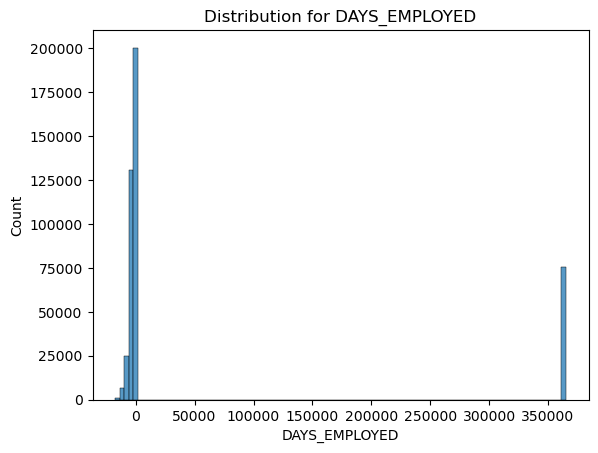

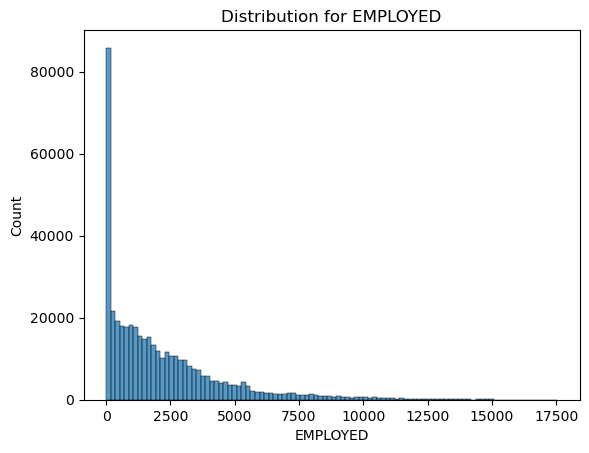

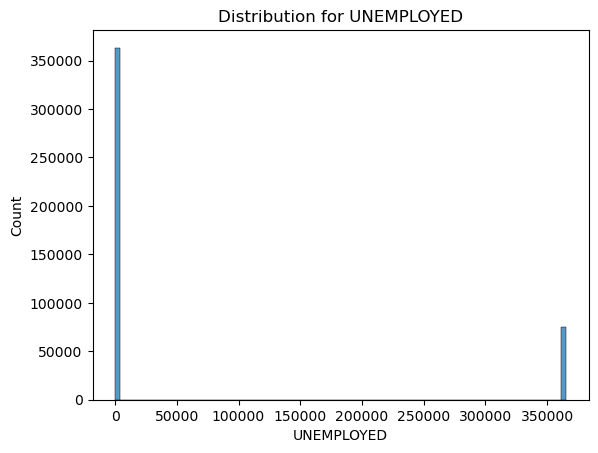

In [93]:
for col in employed.columns: 
    sns.histplot(employed[col], bins = 100 )
    plt.title('Distribution for '+col)
    plt.show()

In [95]:
employed.describe()

,DAYS_EMPLOYED,EMPLOYED,UNEMPLOYED
count,438557.000000,438557.000000,438557.000000
mean,60563.675328,2172.502516,62736.177845
std,138767.799647,2397.398738,137761.261130
min,-17531.000000,0.000000,0.000000
25%,-3103.000000,371.000000,0.000000
50%,-1467.000000,1467.000000,0.000000
75%,-371.000000,3103.000000,0.000000
max,365243.000000,17531.000000,365243.000000


In [ ]:
# this means that there should be robust scaling for employed and just binary encoding for unemployed 
    # unemployed indictator can be done without adding collinarity to df by just setting -1 to employed 
# create scaling pipelines below 

'''
- CNT_CHILDREN, AMT_INCOME_TOTAL, CNT_FAM_MEMBERS = robust scaling for outiers 
- DAYS_BIRTH = minmax for 0-1 scaling 
- DAYS_EMPLOYED should be split into distribution for employed and another distribution for unemployed (positive value)
  - the results below show that there should be robust scaling for employed and just binary encoding for unemployed 
  EMPLOYED = robust scaling, -1 otherwise 
'''

def split_employed(data: pd.DataFrame) -> pd.DataFrame: 
    # ALWAYS make a copy of data, otherwise it mutates in places and this shouldnt happen 

    data = data.copy(deep = True )

    # split the employment column 
    data['EMPLOYED'] = np.where( data.DAYS_EMPLOYED < 0, -data.DAYS_EMPLOYED, -1  )
    data.drop(['DAYS_EMPLOYED'], axis = 1 , inplace =True)

    print(data.info())
    return data 

function_transformed_split_eployed = FunctionTransformer(split_employed) # fit does nothing, and transform runs the function 
    



In [114]:


scalers = ColumnTransformer(
    transformers = [
        ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']),  # employed = transfomed 
        ('minmax', MinMaxScaler( feature_range= (0,1)) , ['DAYS_BIRTH'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False 
).set_output(transform='pandas')

scaling_pipeline = Pipeline(steps = [
    ('split_employed', function_transformed_split_eployed ), 
    ('scaling', scalers),
])


res = scaling_pipeline.fit_transform(apps[numerical])
res

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   ID                438557 non-null  int64  
 1   CNT_CHILDREN      438557 non-null  int64  
 2   AMT_INCOME_TOTAL  438557 non-null  float64
 3   DAYS_BIRTH        438557 non-null  int64  
 4   CNT_FAM_MEMBERS   438557 non-null  float64
 5   EMPLOYED          438557 non-null  int64  
dtypes: float64(2), int64(4)
memory usage: 20.1 MB
None


,CNT_CHILDREN,AMT_INCOME_TOTAL,CNT_FAM_MEMBERS,EMPLOYED,DAYS_BIRTH,ID
0,0.0,2.577000,0.0,1.125549,0.745032,5008804
1,0.0,2.577000,0.0,1.125549,0.745032,5008805
2,0.0,-0.466478,0.0,-0.121889,0.210422,5008806
3,0.0,1.055261,-1.0,0.579795,0.343891,5008808
4,0.0,1.055261,-1.0,0.579795,0.343891,5008809
...,...,...,...,...,...,...
438552,0.0,-0.249087,-1.0,-0.537335,0.140244,6840104
438553,0.0,-0.553435,-1.0,0.563690,0.522922,6840222
438554,0.0,-1.031696,-1.0,-0.400805,0.961608,6841878
438555,0.0,-0.857783,0.0,-0.537335,0.199187,6842765


In [96]:
apps[numerical]

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS
0,5008804,0,427500.0,-12005,-4542,2.0
1,5008805,0,427500.0,-12005,-4542,2.0
2,5008806,0,112500.0,-21474,-1134,2.0
3,5008808,0,270000.0,-19110,-3051,1.0
4,5008809,0,270000.0,-19110,-3051,1.0
...,...,...,...,...,...,...
438552,6840104,0,135000.0,-22717,365243,1.0
438553,6840222,0,103500.0,-15939,-3007,1.0
438554,6841878,0,54000.0,-8169,-372,1.0
438555,6842765,0,72000.0,-21673,365243,2.0


now the scaling and encoding portions are done


combining all together gives: 

In [117]:
df: pd.DataFrame = og_apps.copy(deep = True)
df.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

In [119]:
categorical =df.select_dtypes(include = ['object'] ).columns.to_list()
numerical = df.select_dtypes(include = ['number'] ).columns.to_list()
categorical , numerical 


(['CODE_GENDER',
  'FLAG_OWN_CAR',
  'FLAG_OWN_REALTY',
  'NAME_INCOME_TYPE',
  'NAME_EDUCATION_TYPE',
  'NAME_FAMILY_STATUS',
  'NAME_HOUSING_TYPE',
  'OCCUPATION_TYPE'],
 ['ID',
  'CNT_CHILDREN',
  'AMT_INCOME_TOTAL',
  'DAYS_BIRTH',
  'DAYS_EMPLOYED',
  'FLAG_MOBIL',
  'FLAG_WORK_PHONE',
  'FLAG_PHONE',
  'FLAG_EMAIL',
  'CNT_FAM_MEMBERS'])

In [ ]:
# binary = ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ]  # nominal 
# one_hot = ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'] # nominal 

# ordinal = ['NAME_EDUCATION_TYPE']
# education_order = [
#     'Lower secondary',               # 0: middle school /junior high
#     'Secondary / secondary special', # 1: high school /vocational school
#     'Incomplete higher',             # 2: some college/ university (no degree)
#     'Higher education',              # 3: Bachelor's/ Master's degree
#     'Academic degree'                # 4: PhD / doctorate /post-graduate degree
# ]

# ordinal_pipeline = Pipeline(
#     steps = [('ordinal_endoding', OrdinalEncoder(categories= [education_order])), 
#              ('scaling', MinMaxScaler())]
# )

# transformer = ColumnTransformer(
#     transformers=[
#         ('binary', OrdinalEncoder(), binary), 
#         ('onehot', OneHotEncoder(sparse_output=False), one_hot), 
#         ('ordinal', ordinal_pipeline, ordinal )
#     ], 
#     remainder='passthrough', 
#     verbose_feature_names_out=False
# ).set_output(transform='pandas')


# fitted = transformer.fit_transform(apps)
# fitted.head()

In [ ]:

# def split_employed(data: pd.DataFrame) -> pd.DataFrame: 
#     # ALWAYS make a copy of data, otherwise it mutates in places and this shouldnt happen 

#     data = data.copy(deep = True )

#     # split the employment column 
#     data['EMPLOYED'] = np.where( data.DAYS_EMPLOYED < 0, -data.DAYS_EMPLOYED, -1  )
#     data.drop(['DAYS_EMPLOYED'], axis = 1 , inplace =True)

#     print(data.info())
#     return data 

# function_transformed_split_eployed = FunctionTransformer(split_employed) # fit does nothing, and transform runs the function 

# scalers = ColumnTransformer(
#     transformers = [
#         ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']),  # employed = transfomed 
#         ('minmax', MinMaxScaler( feature_range= (0,1)) , ['DAYS_BIRTH'])
#     ], 
#     remainder= 'passthrough', 
#     verbose_feature_names_out=False 
# ).set_output(transform='pandas')

# scaling_pipeline = Pipeline(steps = [
#     ('split_employed', function_transformed_split_eployed ), 
#     ('scaling', scalers),
# ])


# res = scaling_pipeline.fit_transform(apps[numerical])

In [122]:
# preprocessing step 
    # drop FLAG_MOBIL
    # split DAYS_EMPLOYED

def preprocess(data: pd.DataFrame) -> pd.DataFrame: 
    # always take copy, so that the df isnt changed in place 
    # func only for transform not fit 
    data = data.copy(deep = True)

    data['EMPLOYED'] = np.where( data['DAYS_EMPLOYED'] <=0, -data['DAYS_EMPLOYED'], -1 )
        # turn into positive days employed and -1 = unemployed 

    data.drop(labels = ['FLAG_MOBIL', 'DAYS_EMPLOYED' ], axis  = 1 , inplace= True )
    return data 

function_transfomer_preprocess= FunctionTransformer(preprocess)


# encoding step 
    # binary 
    # onehot 
    # ordinal 
    # prevent sparse 
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

encoders = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ), # no missing vals in df no need to worry about encoding missing values 
        ('ordinal', OrdinalEncoder(categories = [education_order]), ['NAME_EDUCATION_TYPE']), 
        ('one_hot', OneHotEncoder(sparse_output=False), ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False # auto for onehot encoded 
).set_output(transform='pandas')

scalers = ColumnTransformer(
    transformers = [
        ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']), 
        ('minmax', MinMaxScaler(), ['DAYS_BIRTH']), 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out= False 
).set_output(transform='pandas')

pipeline = Pipeline(
    steps = [
        ('column_preprocessing', function_transfomer_preprocess), 
        ('encoders', encoders), 
        ('scalers', scalers)
    ]
).set_output(transform = 'pandas')

transformed_df = pipeline.fit_transform(df)
transformed_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 48 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   CNT_CHILDREN                             438557 non-null  float64
 1   AMT_INCOME_TOTAL                         438557 non-null  float64
 2   CNT_FAM_MEMBERS                          438557 non-null  float64
 3   EMPLOYED                                 438557 non-null  float64
 4   DAYS_BIRTH                               438557 non-null  float64
 5   CODE_GENDER                              438557 non-null  float64
 6   FLAG_OWN_CAR                             438557 non-null  float64
 7   FLAG_OWN_REALTY                          438557 non-null  float64
 8   NAME_EDUCATION_TYPE                      438557 non-null  float64
 9   NAME_INCOME_TYPE_Commercial associate    438557 non-null  float64
 10  NAME_INCOME_TYPE_Pensioner      

In [ ]:
transformed_df.to_csv('../data_saved/data_processing/data_exploration_final_apps.csv', index = False )

In [125]:
transformed_df.describe()

,CNT_CHILDREN,AMT_INCOME_TOTAL,CNT_FAM_MEMBERS,EMPLOYED,DAYS_BIRTH,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE_Commercial associate,...,OCCUPATION_TYPE_Realty agents,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL
count,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,...,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000
mean,0.427390,0.258394,0.194465,0.258174,0.519597,0.328616,0.371897,0.693351,1.562709,0.229747,...,0.002374,0.093712,0.004661,0.018226,0.003797,0.306010,6.022176e+06,0.206133,0.287771,0.108207
std,0.724882,1.063641,0.897207,0.877582,0.236282,0.469711,0.483312,0.461103,0.897085,0.420670,...,0.048663,0.291428,0.068110,0.133767,0.061499,0.460835,5.716370e+05,0.404527,0.452724,0.310642
min,0.000000,-1.301261,-1.000000,-0.537335,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.008804e+06,0.000000,0.000000,0.000000
25%,0.000000,-0.379522,0.000000,-0.401171,0.322832,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.609375e+06,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.540368,0.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.047745e+06,0.000000,0.000000,0.000000
75%,1.000000,0.620478,1.000000,0.598829,0.716294,1.000000,1.000000,1.000000,3.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.456971e+06,0.000000,1.000000,0.000000
max,19.000000,63.663957,18.000000,5.879941,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.999952e+06,1.000000,1.000000,1.000000


In [127]:
og_apps.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


<Axes: >

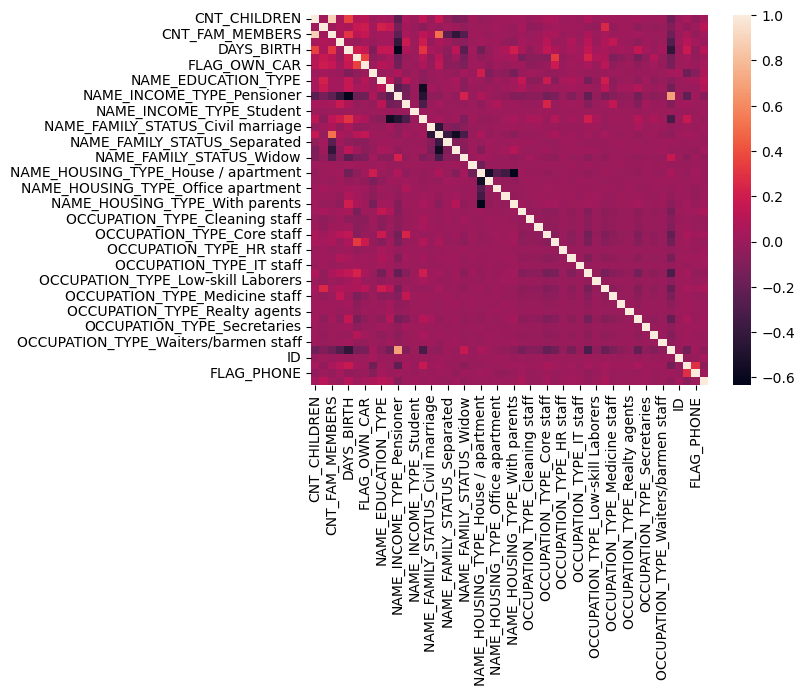

In [126]:
sns.heatmap(transformed_df.corr())

there is a bit of an issue with the ranges here 

the robust scaler div by iqr so the outliers still exist, and also the ordinally encoded var is on a scale from 0-5 

do PowerTransformer(standardize=False) first to squash the skewness into a bell shape, and then use RobustScaler second so any remaining extreme tails don't distort your final centering and scaling
 - power transformer pulls extreme tails inward to make every column roughly gaussian (bell-shaped) and automatically standardizes them to mean 0, std 1

to center and scale all the data, use standard scaler 
    - -1 to 1 is better and allows nn to train faster than 0 to 1 

so, add steps to the pipeline where there is powertransformer (without standardize) first ON ONLY the numerical variables, then all the encoding steps, then the scaling steps, then finally do a standard scale to fix ordinal values 
    - standard scaling can be done multiple times bc mathematically it is the same 
    - however, doing standard scaling on binary encoded variables is a bad idea (can amplify noise, and non interpretable, and they are already between 0 and 1)
    - keep the powertransformer and standard scaling on the numerical features 
      - should do stanrad scaling on ordinal if using nn, vsm, knn, linar- but not on tree methods 


In [128]:
from sklearn.preprocessing import PowerTransformer

In [130]:
# preprocessing step 
    # drop FLAG_MOBIL
    # split DAYS_EMPLOYED

def preprocess(data: pd.DataFrame) -> pd.DataFrame: 
    # always take copy, so that the df isnt changed in place 
    # func only for transform not fit 
    data = data.copy(deep = True)

    data['EMPLOYED'] = np.where( data['DAYS_EMPLOYED'] <=0, -data['DAYS_EMPLOYED'], -1 )
        # turn into positive days employed and -1 = unemployed 

    data.drop(labels = ['FLAG_MOBIL', 'DAYS_EMPLOYED' ], axis  = 1 , inplace= True )
    return data 

function_transfomer_preprocess= FunctionTransformer(preprocess)


# encoding step 
    # binary 
    # onehot 
    # ordinal 
    # prevent sparse 
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

encoders = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ), # no missing vals in df no need to worry about encoding missing values 
        ('ordinal', OrdinalEncoder(categories = [education_order]), ['NAME_EDUCATION_TYPE']), 
        ('one_hot', OneHotEncoder(sparse_output=False), ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False # auto for onehot encoded 
).set_output(transform='pandas')

scalers = ColumnTransformer(
    transformers = [
        ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']), 
        ('minmax', MinMaxScaler(), ['DAYS_BIRTH']), 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out= False 
).set_output(transform='pandas')


squash_skew= ColumnTransformer(
    transformers= [
        ('squash_skewness', PowerTransformer(method = 'yeo-johnson', standardize=False), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED'] ), 
                    # this will sqash skewness for the numerical non min-maxed features 
                    # remaining tails are dealt with robust scaler 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out=False 
).set_output(transform='pandas')


pipeline = Pipeline(
    steps = [
        ('column_preprocessing', function_transfomer_preprocess), 
        ('squash_skeq', squash_skew), 
        ('encoders', encoders), 
        ('scalers', scalers)
    ]
).set_output(transform = 'pandas')

transformed_df = pipeline.fit_transform(df)
transformed_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 48 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   CNT_CHILDREN                             438557 non-null  float64
 1   AMT_INCOME_TOTAL                         438557 non-null  float64
 2   CNT_FAM_MEMBERS                          438557 non-null  float64
 3   EMPLOYED                                 438557 non-null  float64
 4   DAYS_BIRTH                               438557 non-null  float64
 5   CODE_GENDER                              438557 non-null  float64
 6   FLAG_OWN_CAR                             438557 non-null  float64
 7   FLAG_OWN_REALTY                          438557 non-null  float64
 8   NAME_EDUCATION_TYPE                      438557 non-null  float64
 9   NAME_INCOME_TYPE_Commercial associate    438557 non-null  float64
 10  NAME_INCOME_TYPE_Pensioner      

In [131]:
transformed_df.describe()

,CNT_CHILDREN,AMT_INCOME_TOTAL,CNT_FAM_MEMBERS,EMPLOYED,DAYS_BIRTH,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE_Commercial associate,...,OCCUPATION_TYPE_Realty agents,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL
count,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,...,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000
mean,0.317745,0.042668,0.072225,-0.128508,0.519597,0.328616,0.371897,0.693351,1.562709,0.229747,...,0.002374,0.093712,0.004661,0.018226,0.003797,0.306010,6.022176e+06,0.206133,0.287771,0.108207
std,0.478597,0.768839,0.962795,0.801951,0.236282,0.469711,0.483312,0.461103,0.897085,0.420670,...,0.048663,0.291428,0.068110,0.133767,0.061499,0.460835,5.716370e+05,0.404527,0.452724,0.310642
min,-0.000000,-3.211297,-1.474541,-1.520909,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.008804e+06,0.000000,0.000000,0.000000
25%,0.000000,-0.461442,0.000000,-0.568631,0.322832,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.609375e+06,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.540368,0.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.047745e+06,0.000000,0.000000,0.000000
75%,1.000000,0.538558,1.000000,0.431369,0.716294,1.000000,1.000000,1.000000,3.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.456971e+06,0.000000,1.000000,0.000000
max,1.146014,5.168750,6.088023,1.922521,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.999952e+06,1.000000,1.000000,1.000000


In [132]:
og_apps.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


there is still too high of a range for nn to handle well 

looking at power transform, robust scaler, and standard scaler:
- doing powertransform + robust sclaer + standard scaler just wipes out robust scaling, might as well do powertransform + robust sclaer + standard scaler
- first, test the skewness after just powertransform; then, if it is a bell shape, just apply standard scaling without robust scaler 
  - if there is still high skew after power transform, do powertransform without scaling + robust scaling 

in order to decide, check the skewness after just doing powertransform 

In [133]:
apps: pd.DataFrame = og_apps.copy(deep = True)

In [134]:
# preprocessing step 
    # drop FLAG_MOBIL
    # split DAYS_EMPLOYED

def preprocess(data: pd.DataFrame) -> pd.DataFrame: 
    # always take copy, so that the df isnt changed in place 
    # func only for transform not fit 
    data = data.copy(deep = True)

    data['EMPLOYED'] = np.where( data['DAYS_EMPLOYED'] <=0, -data['DAYS_EMPLOYED'], -1 )
        # turn into positive days employed and -1 = unemployed 

    data.drop(labels = ['FLAG_MOBIL', 'DAYS_EMPLOYED' ], axis  = 1 , inplace= True )
    return data 

function_transfomer_preprocess= FunctionTransformer(preprocess)


# encoding step 
    # binary 
    # onehot 
    # ordinal 
    # prevent sparse 
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

encoders = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ), # no missing vals in df no need to worry about encoding missing values 
        ('ordinal', OrdinalEncoder(categories = [education_order]), ['NAME_EDUCATION_TYPE']), 
        ('one_hot', OneHotEncoder(sparse_output=False), ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False # auto for onehot encoded 
).set_output(transform='pandas')

scalers = ColumnTransformer(
    transformers = [
        # ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']),  # ignore for this round to test skewness after power transform 
        ('minmax', MinMaxScaler(), ['DAYS_BIRTH']), 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out= False 
).set_output(transform='pandas')


squash_skew= ColumnTransformer(
    transformers= [
        ('squash_skewness', PowerTransformer(method = 'yeo-johnson', standardize=False), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED'] ), 
                    # this will sqash skewness for the numerical non min-maxed features 
                    # remaining tails are dealt with robust scaler 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out=False 
).set_output(transform='pandas')


pipeline = Pipeline(
    steps = [
        ('column_preprocessing', function_transfomer_preprocess), 
        ('squash_skeq', squash_skew), 
        ('encoders', encoders), 
        ('scalers', scalers)
    ]
).set_output(transform = 'pandas')

res = pipeline.fit_transform(df)
res.describe()

,DAYS_BIRTH,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,NAME_INCOME_TYPE_Working,...,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,CNT_CHILDREN,AMT_INCOME_TOTAL,CNT_FAM_MEMBERS,EMPLOYED,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL
count,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,...,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000
mean,0.519597,0.328616,0.371897,0.693351,1.562709,0.229747,0.172140,0.082512,0.000039,0.515564,...,0.003797,0.306010,0.093307,7.366581,1.041353,26.027314,6.022176e+06,0.206133,0.287771,0.108207
std,0.236282,0.469711,0.483312,0.461103,0.897085,0.420670,0.377502,0.275143,0.006226,0.499758,...,0.061499,0.460835,0.140541,0.161951,0.235634,15.747277,5.716370e+05,0.404527,0.452724,0.310642
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-0.000000,6.681155,0.662798,-1.314162,5.008804e+06,0.000000,0.000000,0.000000
25%,0.322832,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,7.260394,1.023677,17.384957,5.609375e+06,0.000000,0.000000,0.000000
50%,0.540368,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,7.357594,1.023677,28.550714,6.047745e+06,0.000000,0.000000,0.000000
75%,0.716294,1.000000,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,1.000000,0.293652,7.471038,1.268417,37.021160,6.456971e+06,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.336530,8.446358,2.513657,66.301724,7.999952e+06,1.000000,1.000000,1.000000


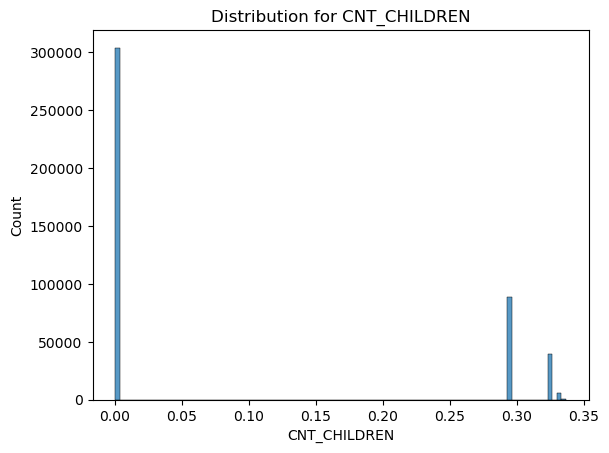

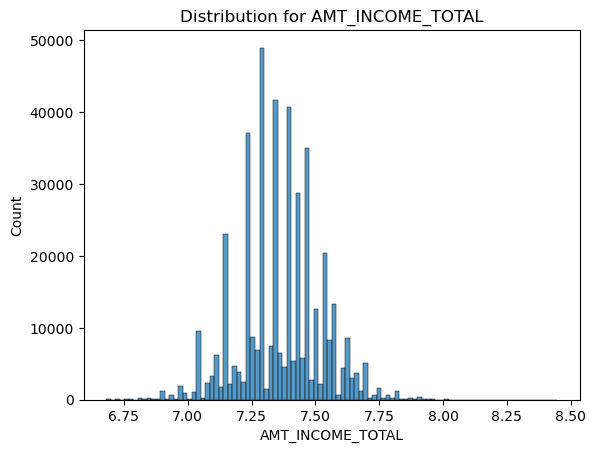

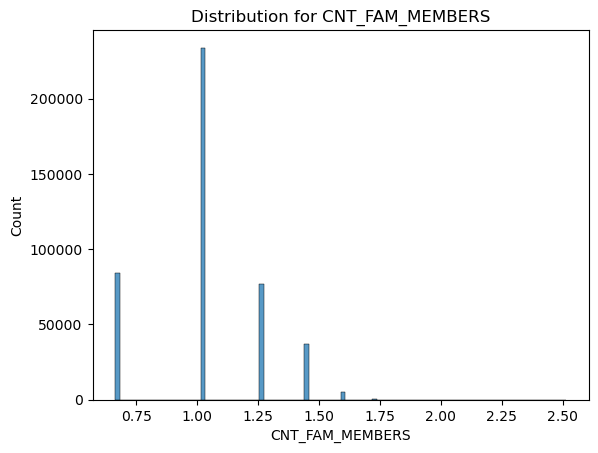

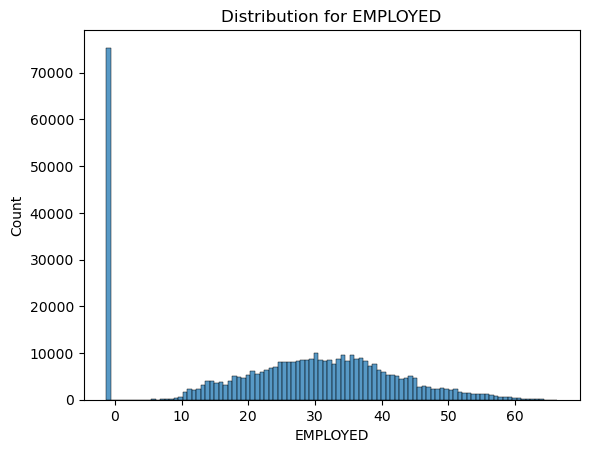

In [135]:
for col in ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']: 
    sns.histplot(res[col], bins = 100 )
    plt.title('Distribution for '+col)
    plt.show()

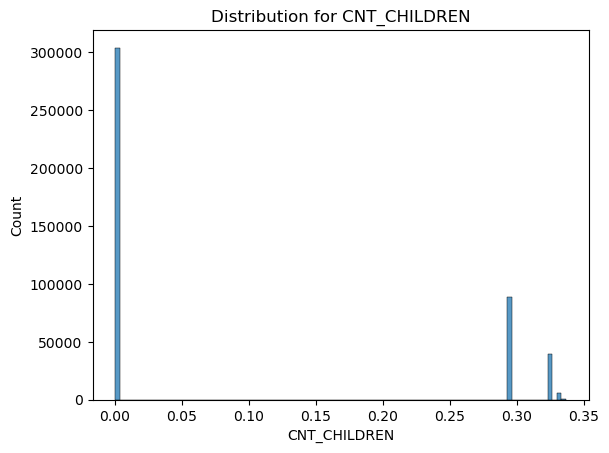

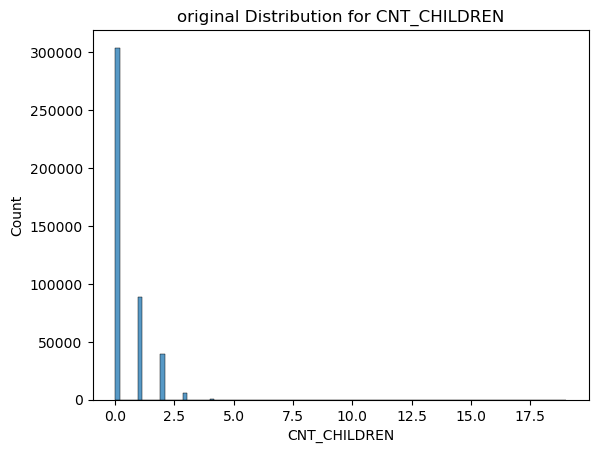

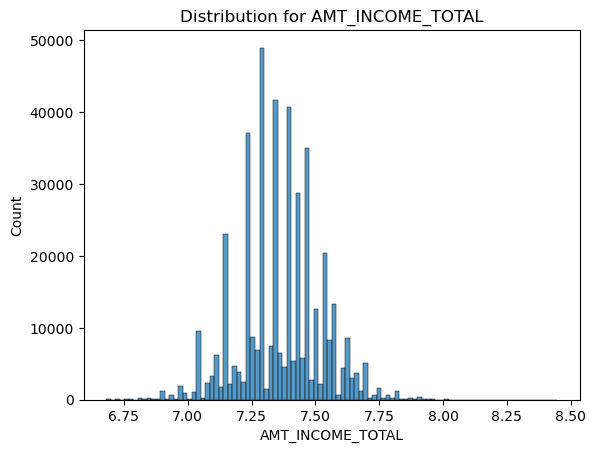

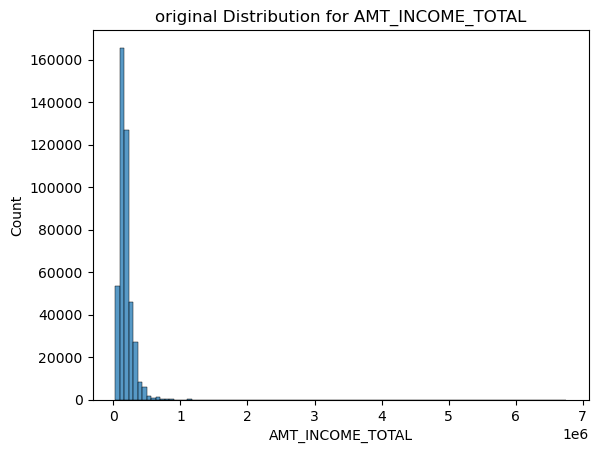

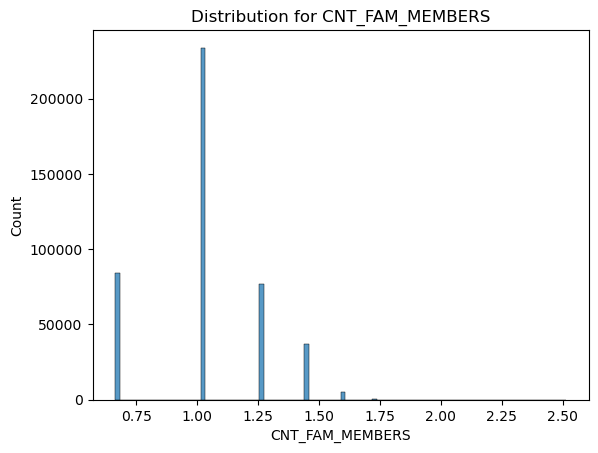

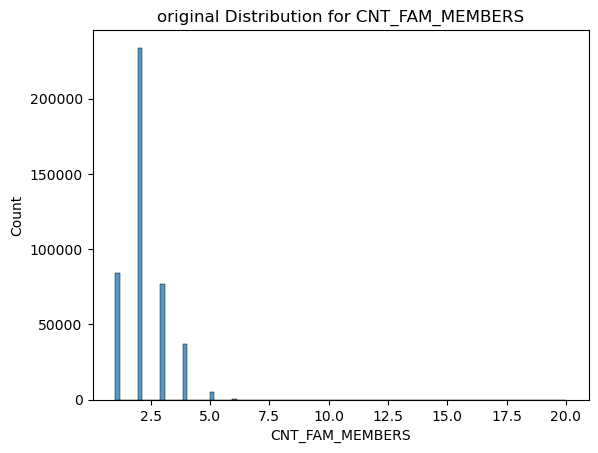

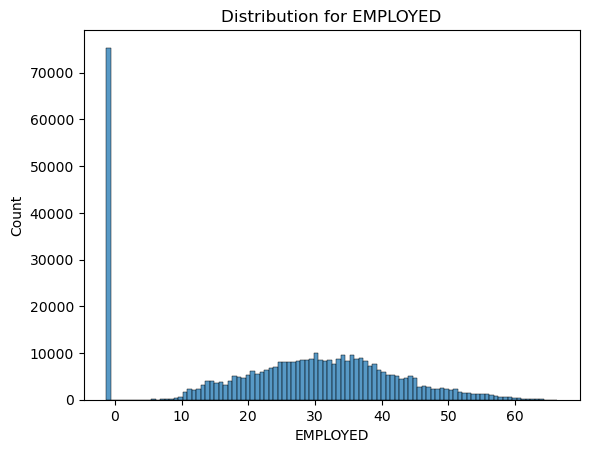

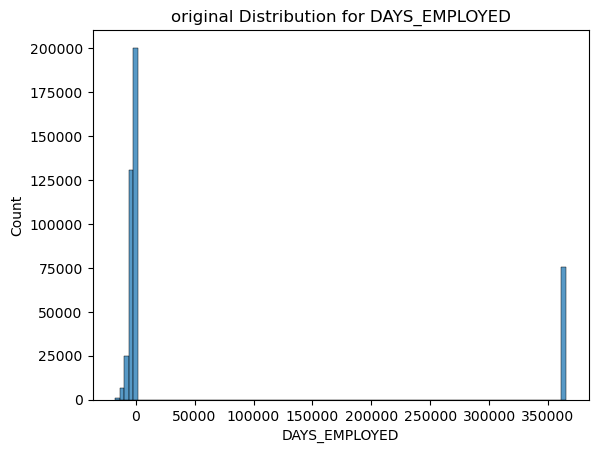

In [138]:
for col in ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']: 
    sns.histplot(res[col], bins = 100 )
    plt.title('Distribution for '+col)
    plt.show()

    if col ==  "EMPLOYED": 
        col = 'DAYS_EMPLOYED'

    sns.histplot(apps[col], bins = 100 )
    plt.title('original Distribution for '+col)
    plt.show()

these results show that the power transformer may be to omuch for some features, see how just robust scaler alone works for family members and count children 

for other features like days employed and amt income total are better off with the power transformer
- however, the days employed would be much better without the -1 value, so make another indicator variable for unemployed where 1 = unemployed

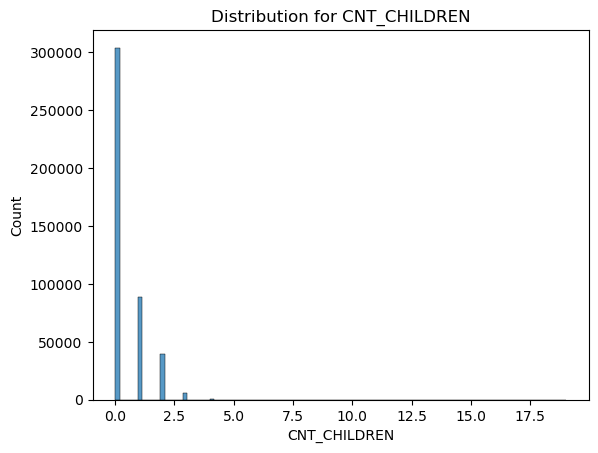

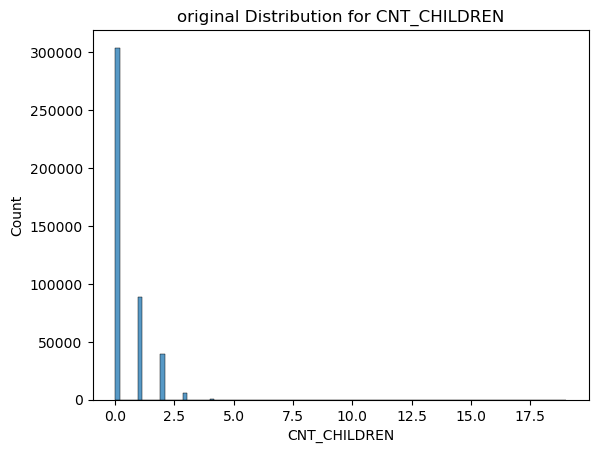

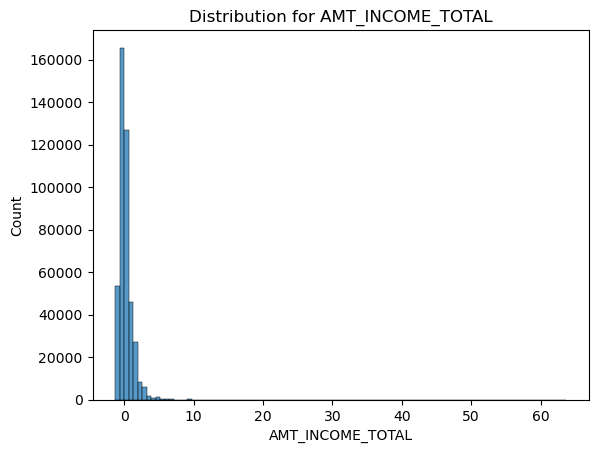

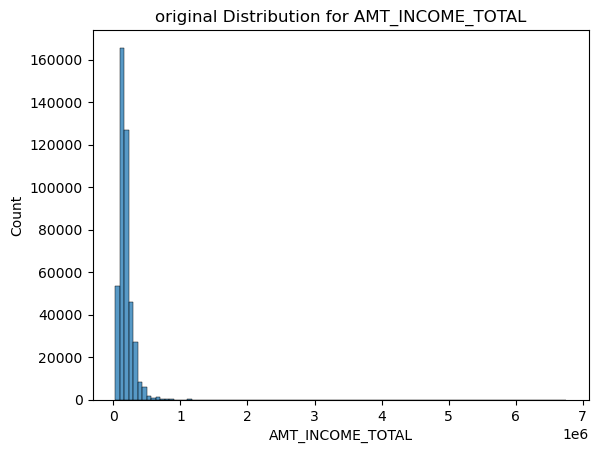

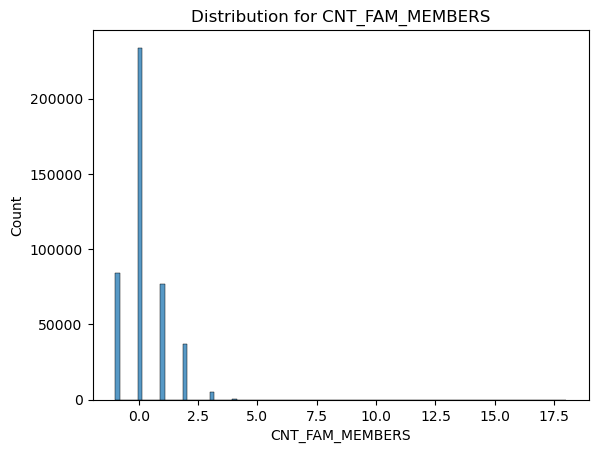

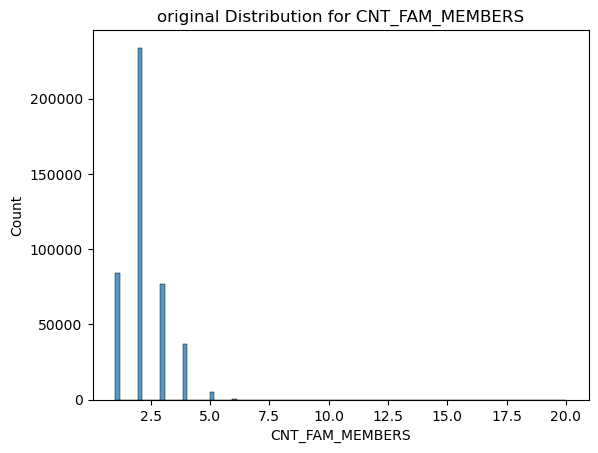

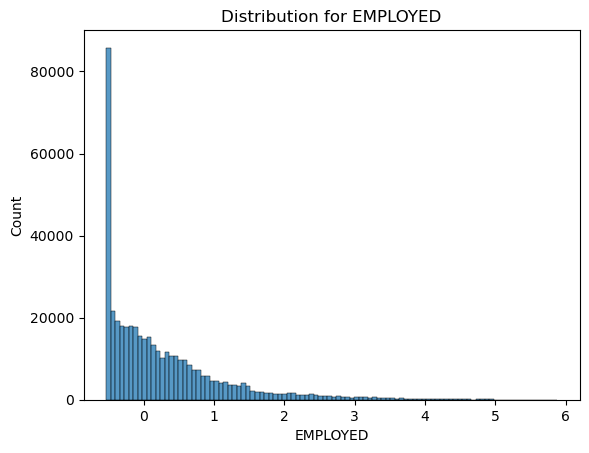

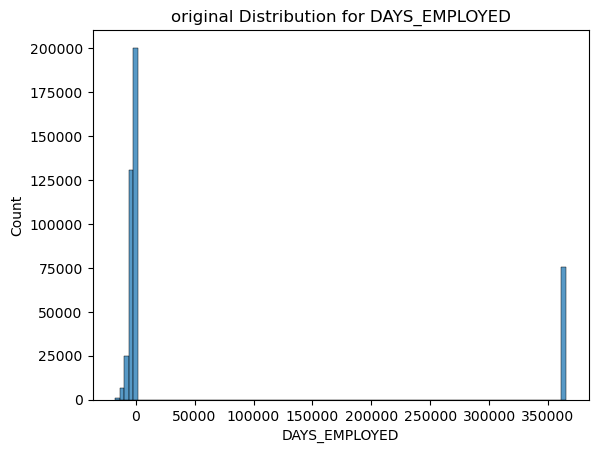

In [139]:
# preprocessing step 
    # drop FLAG_MOBIL
    # split DAYS_EMPLOYED

def preprocess(data: pd.DataFrame) -> pd.DataFrame: 
    # always take copy, so that the df isnt changed in place 
    # func only for transform not fit 
    data = data.copy(deep = True)

    data['EMPLOYED'] = np.where( data['DAYS_EMPLOYED'] <=0, -data['DAYS_EMPLOYED'], -1 )
        # turn into positive days employed and -1 = unemployed 

    data.drop(labels = ['FLAG_MOBIL', 'DAYS_EMPLOYED' ], axis  = 1 , inplace= True )
    return data 

function_transfomer_preprocess= FunctionTransformer(preprocess)


# encoding step 
    # binary 
    # onehot 
    # ordinal 
    # prevent sparse 
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

encoders = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ), # no missing vals in df no need to worry about encoding missing values 
        ('ordinal', OrdinalEncoder(categories = [education_order]), ['NAME_EDUCATION_TYPE']), 
        ('one_hot', OneHotEncoder(sparse_output=False), ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False # auto for onehot encoded 
).set_output(transform='pandas')

scalers = ColumnTransformer(
    transformers = [
        ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']),  # ignore for this round to test skewness after power transform 
        ('minmax', MinMaxScaler(), ['DAYS_BIRTH']), 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out= False 
).set_output(transform='pandas')


squash_skew= ColumnTransformer(
    transformers= [
        ('squash_skewness', PowerTransformer(method = 'yeo-johnson', standardize=False), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED'] ), 
                    # this will sqash skewness for the numerical non min-maxed features 
                    # remaining tails are dealt with robust scaler 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out=False 
).set_output(transform='pandas')


pipeline = Pipeline(
    steps = [
        ('column_preprocessing', function_transfomer_preprocess), 
        # ('squash_skeq', squash_skew), # ignore for now 
        ('encoders', encoders), 
        ('scalers', scalers)
    ]
).set_output(transform = 'pandas')

res = pipeline.fit_transform(df)
res.describe()

for col in ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']: 
    sns.histplot(res[col], bins = 100 )
    plt.title('Distribution for '+col)
    plt.show()

    if col ==  "EMPLOYED": 
        col = 'DAYS_EMPLOYED'

    sns.histplot(apps[col], bins = 100 )
    plt.title('original Distribution for '+col)
    plt.show()

nww just use standard scaler to see how the distributions lay 

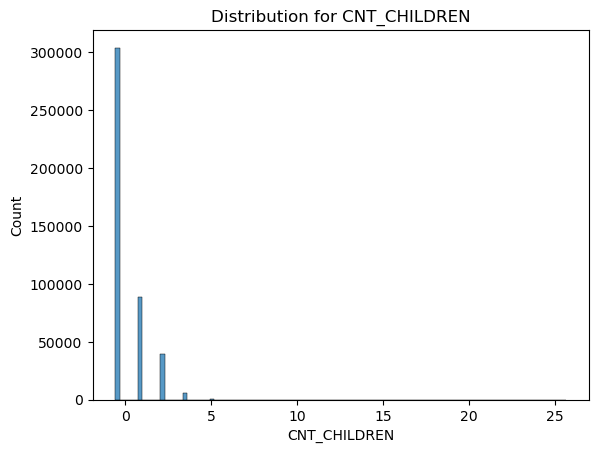

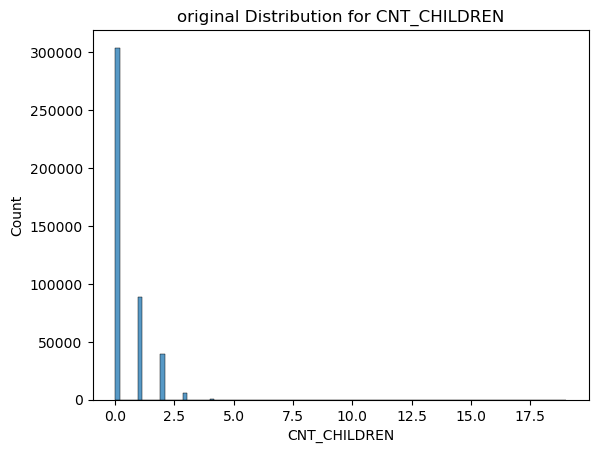

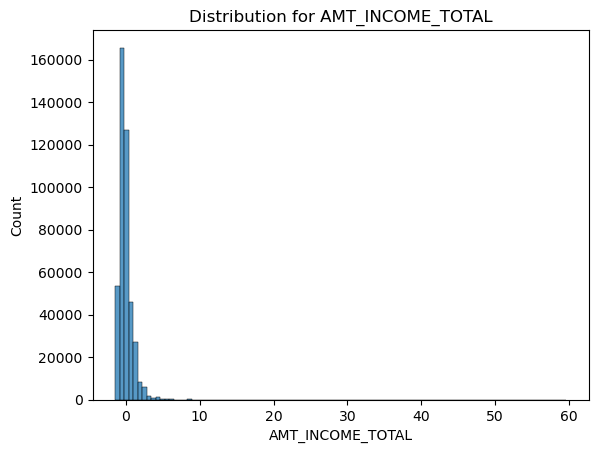

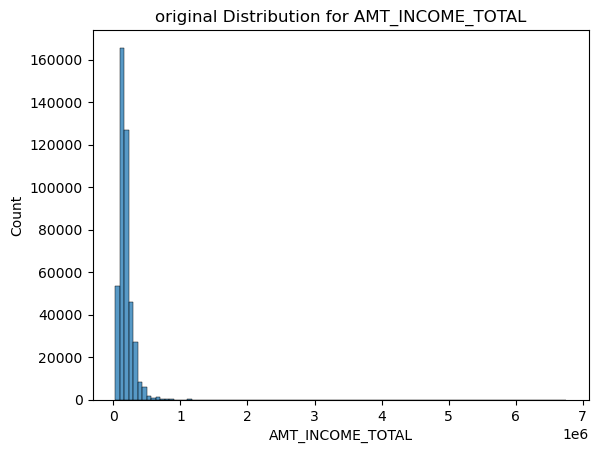

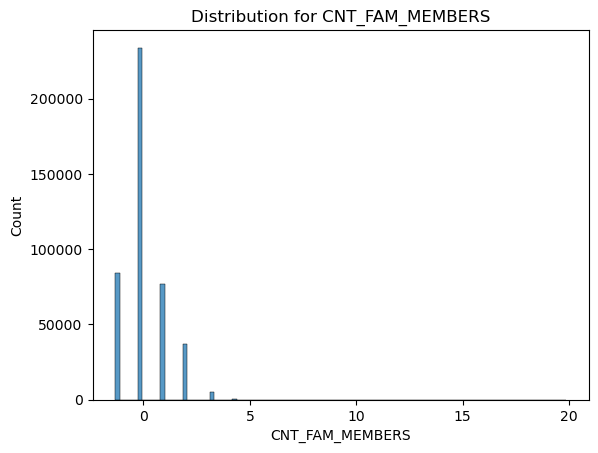

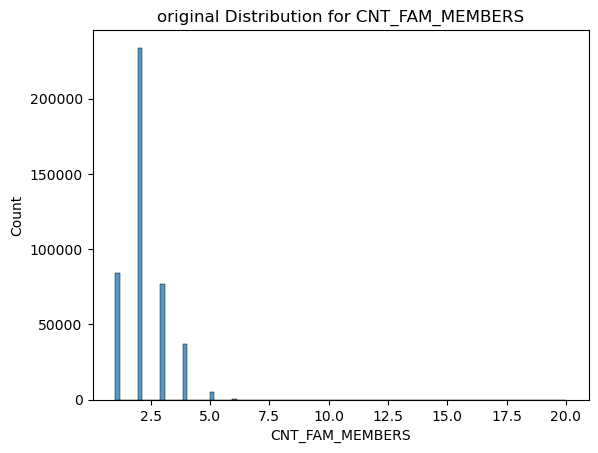

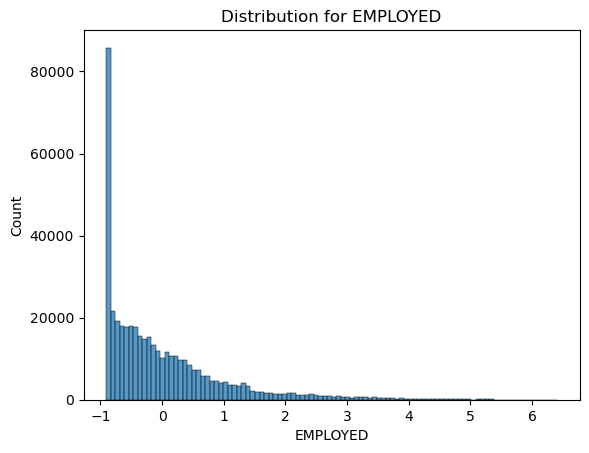

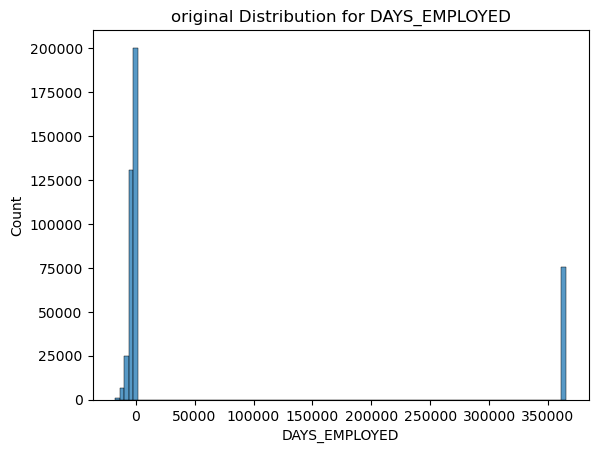

In [140]:
# preprocessing step 
    # drop FLAG_MOBIL
    # split DAYS_EMPLOYED

def preprocess(data: pd.DataFrame) -> pd.DataFrame: 
    # always take copy, so that the df isnt changed in place 
    # func only for transform not fit 
    data = data.copy(deep = True)

    data['EMPLOYED'] = np.where( data['DAYS_EMPLOYED'] <=0, -data['DAYS_EMPLOYED'], -1 )
        # turn into positive days employed and -1 = unemployed 

    data.drop(labels = ['FLAG_MOBIL', 'DAYS_EMPLOYED' ], axis  = 1 , inplace= True )
    return data 

function_transfomer_preprocess= FunctionTransformer(preprocess)


# encoding step 
    # binary 
    # onehot 
    # ordinal 
    # prevent sparse 
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]

encoders = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ), # no missing vals in df no need to worry about encoding missing values 
        ('ordinal', OrdinalEncoder(categories = [education_order]), ['NAME_EDUCATION_TYPE']), 
        ('one_hot', OneHotEncoder(sparse_output=False), ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False # auto for onehot encoded 
).set_output(transform='pandas')

scalers = ColumnTransformer(
    transformers = [
        ('robust', StandardScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']),  # try this
        ('minmax', MinMaxScaler(), ['DAYS_BIRTH']), 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out= False 
).set_output(transform='pandas')


squash_skew= ColumnTransformer(
    transformers= [
        ('squash_skewness', PowerTransformer(method = 'yeo-johnson', standardize=False), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED'] ), 
                    # this will sqash skewness for the numerical non min-maxed features 
                    # remaining tails are dealt with robust scaler 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out=False 
).set_output(transform='pandas')


pipeline = Pipeline(
    steps = [
        ('column_preprocessing', function_transfomer_preprocess), 
        # ('squash_skeq', squash_skew), # ignore for now 
        ('encoders', encoders), 
        ('scalers', scalers)
    ]
).set_output(transform = 'pandas')

res = pipeline.fit_transform(df)
res.describe()

for col in ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']: 
    sns.histplot(res[col], bins = 100 )
    plt.title('Distribution for '+col)
    plt.show()

    if col ==  "EMPLOYED": 
        col = 'DAYS_EMPLOYED'

    sns.histplot(apps[col], bins = 100 )
    plt.title('original Distribution for '+col)
    plt.show()


the power transformer is functioning well for AMT_INCOME_TOTAL and EMPLOYED
    - make indicator variable for UNEMPLOYED and remove for employed 
  
use QuantileTransformer(output_distribution='normal') or np.log1p + RobustScaler for CNT_CHILDREN and CNT_FAM_MEMBERS 
    - standard scaler vs robust scaler doesnt change large range for these features 
    - this tames the large range of values, and makes it within 0 and 1 for the nn 
  
apply standard scaling for the ordinal encoding 
    - prevent too large of scale 

In [144]:
# preprocessing step 
    # drop FLAG_MOBIL
    # split DAYS_EMPLOYED

def preprocess(data: pd.DataFrame) -> pd.DataFrame: 
    # always take copy, so that the df isnt changed in place 
    # func only for transform not fit 
    data = data.copy(deep = True)

    data['EMPLOYED'] = np.where( data['DAYS_EMPLOYED'] <=0, -data['DAYS_EMPLOYED'], -1 )
    data['UNEMPLOYED'] = np.where( data['DAYS_EMPLOYED'] > 0, 1, 0 ) # indicator binary variable 
        # turn into positive days employed and -1 = unemployed 

    data.drop(labels = ['FLAG_MOBIL', 'DAYS_EMPLOYED' ], axis  = 1 , inplace= True )
    return data 

function_transfomer_preprocess= FunctionTransformer(preprocess)
function_transformer_natural_log =FunctionTransformer( func = np.log1p) # not () for log call 

# encoding step 
    # binary 
    # onehot 
    # ordinal 
    # prevent sparse 
education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
]


squash_skew= ColumnTransformer( # will be put through robust scaler later down the pipeline 
    transformers= [
        ('squash_skewness', PowerTransformer(method = 'yeo-johnson', standardize=False), ['AMT_INCOME_TOTAL', 'EMPLOYED'] ), 
                    # this will sqash skewness for the numerical non min-maxed features 
                    # remaining tails are dealt with robust scaler 
        ('compress_outliers', function_transformer_natural_log,  ['CNT_CHILDREN', 'CNT_FAM_MEMBERS'])
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out=False 
).set_output(transform='pandas')


encoders = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), ['CODE_GENDER','FLAG_OWN_CAR', 'FLAG_OWN_REALTY' ] ), # no missing vals in df no need to worry about encoding missing values 
        ('ordinal', OrdinalEncoder(categories = [education_order]), ['NAME_EDUCATION_TYPE']), 
        ('one_hot', OneHotEncoder(sparse_output=False), ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'])
    ], 
    remainder= 'passthrough', 
    verbose_feature_names_out=False # auto for onehot encoded 
).set_output(transform='pandas')

scalers = ColumnTransformer(
    transformers = [
        ('robust', RobustScaler(), ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'EMPLOYED']),  # try this
        ('minmax', MinMaxScaler(), ['DAYS_BIRTH']),
        ('standard_scale_ordinal', StandardScaler(), ['NAME_EDUCATION_TYPE']) 
    ], 
    remainder = 'passthrough', 
    verbose_feature_names_out= False 
).set_output(transform='pandas')


pipeline = Pipeline(
    steps = [
        ('column_preprocessing', function_transfomer_preprocess), 
        ('squash_skeq', squash_skew), # ignore for now 
        ('encoders', encoders), 
        ('scalers', scalers)
    ]
).set_output(transform = 'pandas')

transformed_df = pipeline.fit_transform(df)
transformed_df.describe()


,CNT_CHILDREN,AMT_INCOME_TOTAL,CNT_FAM_MEMBERS,EMPLOYED,DAYS_BIRTH,NAME_EDUCATION_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE_Commercial associate,...,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,UNEMPLOYED
count,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000,438557.000000,...,438557.000000,438557.000000,438557.000000,438557.000000,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000,438557.000000
mean,0.374318,0.042668,0.087823,-0.128508,0.519597,-1.094920e-16,0.328616,0.371897,0.693351,0.229747,...,0.093712,0.004661,0.018226,0.003797,0.306010,6.022176e+06,0.206133,0.287771,0.108207,0.171766
std,0.590244,0.768839,0.948914,0.801951,0.236282,1.000001e+00,0.469711,0.483312,0.461103,0.420670,...,0.291428,0.068110,0.133767,0.061499,0.460835,5.716370e+05,0.404527,0.452724,0.310642,0.377177
min,0.000000,-3.211297,-1.409421,-1.520909,0.000000,-1.741988e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,5.008804e+06,0.000000,0.000000,0.000000,0.000000
25%,0.000000,-0.461442,0.000000,-0.568631,0.322832,-6.272649e-01,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,5.609375e+06,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.540368,-6.272649e-01,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,6.047745e+06,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.538558,1.000000,0.431369,0.716294,1.602182e+00,1.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.456971e+06,0.000000,1.000000,0.000000,0.000000
max,4.321928,5.168750,6.764099,1.922521,1.000000,2.716905e+00,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,7.999952e+06,1.000000,1.000000,1.000000,1.000000


In [145]:
# for col in res.columns: 
#     sns.histplot(res[col], bins = 100 )
#     plt.title('Distribution for '+col)
#     plt.show()

# res.skew().sort_values(ascending=False) # high skew if < -1 or > + 1 // .5s mean medium // less than .5 closer to 0 is symmetrical 


transformed_df.to_csv('../data_saved/data_processing/data_exploration_final_apps.csv', index = False )

- encoding step first 
  ['CODE_GENDER' - binary 
  'FLAG_OWN_CAR', - binary 
  'FLAG_OWN_REALTY', - binary 
  'NAME_INCOME_TYPE', - onehot 
  'NAME_EDUCATION_TYPE', - ordinal 
  'NAME_FAMILY_STATUS', - onehot 
  'NAME_HOUSING_TYPE', - onehot 
  'OCCUPATION_TYPE'] - onehot, nans get encoded into their own column  


- scaling step 
  ['ID', 
  'CNT_CHILDREN', - natural log + robust 
  'AMT_INCOME_TOTAL', - power transformer + robust 
  'DAYS_BIRTH', - minmax 
  'DAYS_EMPLOYED', - transformed into EMPLOYED (power transformer + robust), unemployed is -1 
  'FLAG_MOBIL', - dropped 
  'FLAG_WORK_PHONE', 
  'FLAG_PHONE',
  'FLAG_EMAIL',
  'CNT_FAM_MEMBERS'] - natural log + robust 
  - no need to scale binary encoded or already binary like the numerical flags 

# all changes 

- dropped FLAG_MOBIL 
- OCCUPATION_TYPE 
  - 30 percent of the occupation type feature is missing, if the feature is generally uninformative in corr matrix, it can be removed -- no informative, keep in df 
- NAME_EDUCATION_TYPE is ordinal encoding  
  - education_order = [
    'Lower secondary',               # 0: middle school /junior high
    'Secondary / secondary special', # 1: high school /vocational school
    'Incomplete higher',             # 2: some college/ university (no degree)
    'Higher education',              # 3: Bachelor's/ Master's degree
    'Academic degree'                # 4: PhD / doctorate /post-graduate degree
    ]


- CODE_GENDER,FLAG_OWN_CAR, FLAG_OWN_REALTY is binary encoding (ordinal )
- other categrorical features will be one hot encoded 

numerical features: 
- CNT_CHILDREN, CNT_FAM_MEMBERS = natural log + robust scaling for outiers 
- AMT_INCOME_TOTAL = power transformer + robust 
- DAYS_BIRTH = minmax for 0-1 scaling 
- DAYS_EMPLOYED should be split into distribution for employed and another distribution for unemployed (positive value)
  - EMPLOYED power transformer + robust scaling for employed 
  - binary encoding for unemployed, this is done through setting 1 to unemployed 